<a href="https://colab.research.google.com/github/momensaleh193-png/Machine-learning-course/blob/main/week11_CNNs_transfer_YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="text-align: right; font-size: 28px; font-weight: bold; background: linear-gradient(135deg, #1a1a2e 0%, #16213e 100%); padding: 20px; border-radius: 10px; margin-bottom: 20px;">

# Week 11: CNN Architectures, Transfer Learning & YOLO

بعد ما اتعلمنا الـ Deep Learning والـ Sequence Models
دلوقتي يلا بينا نشوف Computer Vision مع CNN وYOLO

 النهاردة هنطبقها على صور حقيقية بإذن الله

</div>


## Overview

**Instructor:** Dr. Mahmoud Eid (m.eid@fci-cu.edu.eg)

**Estimated Time:** 4-5 hours

**I have already uploaded the datasets on my google drive so you just access that by running the code and don't worry about manually downloading them**

**What You'll Learn:**

**Custom CNN Architecture on CIFAR-10**

- Build CNN from scratch with convolutional and pooling layers
- Train on CIFAR-10 dataset (10 classes, 60,000 images)
- Understand conv layers, max pooling, dropout, batch normalization

**Transfer Learning with ResNet50**

- Load pre-trained ResNet50
- Use it as feature extractor
- Fine-tune on new custom data

**YOLO Object Detection**

- Understand YOLO architecture
- Implement custom CNN and experiment with transfer learning

**Two tasks: building a CNN and augmenting data**

**Prerequisites:** PyTorch basics (Week 5+), CNNs (Lectures 19 and 20)


---

## Setup and Imports

In [1]:
!pip install -q gdown ultralytics

import os
import gdown
import zipfile


ZIP_FILE_ID = "1P6bjXhXxDOgou2_3FHu3OaHq-YaLgwr8"  # my google drive folder ID that contains the needed datasets

if not os.path.exists('/content/week11_data'):
    print("Downloading data from Google Drive...")
    url = f"https://drive.google.com/uc?id={ZIP_FILE_ID}"
    gdown.download(url, '/content/week11_data.zip', quiet=False)

    print("\nExtracting data ...")
    with zipfile.ZipFile('/content/week11_data.zip', 'r') as zip_ref:
        zip_ref.extractall('/content/')

    os.remove('/content/week11_data.zip')
    print("Done!")
else:
    print("Data already exists, skipping download.")

import platform
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as transforms
from torchvision.models import vgg19, VGG19_Weights
from torchvision.datasets import CIFAR10
import warnings
warnings.filterwarnings('ignore')

plt.style.use('dark_background')
np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {device}")
print(f"PyTorch version: {torch.__version__}")

NUM_WORKERS = 2

DATA_PATH = "/content/week11_data/data"
POTHOLE_PATH = "/content/week11_data/Pothole Dataset"

print(f"\nData paths:")
print(f"  CIFAR-10 & Pets: {DATA_PATH} - {'OK' if os.path.exists(DATA_PATH) else 'NOT FOUND!'}")
print(f"  Pothole Dataset: {POTHOLE_PATH} - {'OK' if os.path.exists(POTHOLE_PATH) else 'NOT FOUND!'}")

Downloading...
From (original): https://drive.google.com/uc?id=1P6bjXhXxDOgou2_3FHu3OaHq-YaLgwr8
From (redirected): https://drive.google.com/uc?id=1P6bjXhXxDOgou2_3FHu3OaHq-YaLgwr8&confirm=t&uuid=ca84a341-3d3c-4254-b615-9cdcde6f7929
To: /content/week11_data.zip
100%|██████████| 2.15G/2.15G [00:28<00:00, 75.2MB/s]



Extracting data ...
Done!

Using device: cuda
PyTorch version: 2.14.1+cu130

Data paths:
  CIFAR-10 & Pets: /content/week11_data/data - OK
  Pothole Dataset: /content/week11_data/Pothole Dataset - OK


---

<div dir="rtl" style="text-align: right; font-size: 22px; font-weight: bold; background-color: #1a1a2e; padding: 15px; border-radius: 10px;">

# part 1: Custom CNN Architecture on CIFAR-10

</div>

**Task:** Build a CNN from scratch and train it on CIFAR-10 dataset

**CIFAR-10:** 10 classes (airplane, car, bird, cat, deer, dog, frog, horse, ship, truck)


## Step 1: Load and Visualize CIFAR-10

In [2]:
# Define transformations
transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2470, 0.2435, 0.2616])
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2470, 0.2435, 0.2616])
])

train_dataset = CIFAR10(root=DATA_PATH, train=True, download=False, transform=transform_train)
test_dataset = CIFAR10(root=DATA_PATH, train=False, download=False, transform=transform_test)

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS)

# CIFAR-10 class names
class_names = ['airplane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Train batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")
print(f"\nClasses: {class_names}")

Training samples: 50000
Test samples: 10000
Train batches: 391
Test batches: 79

Classes: ['airplane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


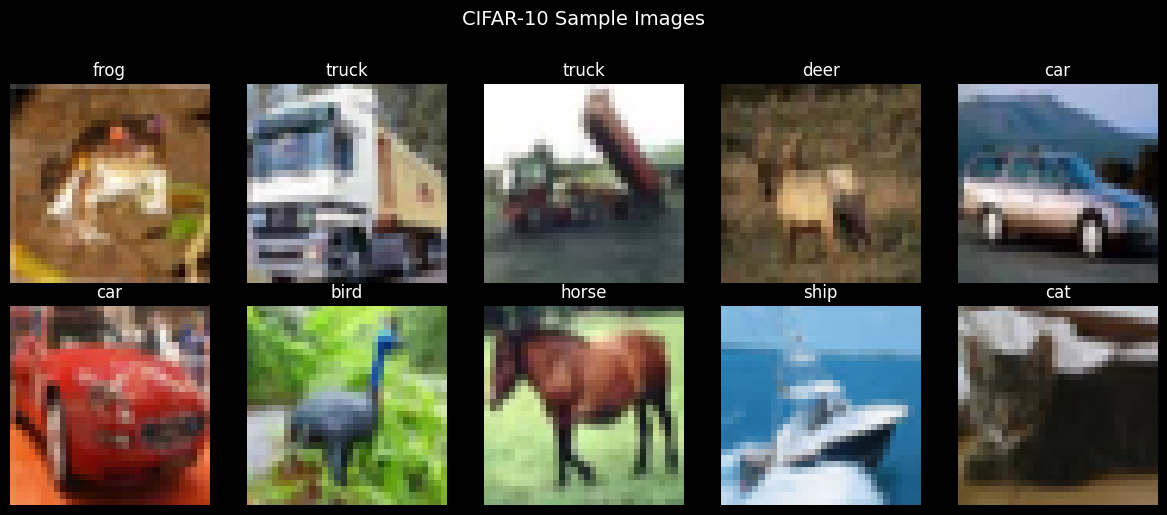

CIFAR-10 loaded and visualized!


In [3]:
display_dataset = CIFAR10(root=DATA_PATH, train=True, download=False, transform=transforms.ToTensor())

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("CIFAR-10 Sample Images", fontsize=14, y=1.02)

for i, ax in enumerate(axes.flat):
    img, label = display_dataset[i]
    img = img.permute(1, 2, 0)  # CHW -> HWC
    ax.imshow(img)
    ax.set_title(f"{class_names[label]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

print("CIFAR-10 loaded and visualized!")

## Step 2: Define Custom CNN Architecture


In [4]:
class CustomCNN(nn.Module):
    """
    Custom CNN for CIFAR-10 Classification
    """

    def __init__(self, num_classes=10):
        super(CustomCNN, self).__init__()

        # Conv Block 1: 3 → 32 channels
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 32x32 → 16x16
            nn.Dropout(0.2)
        )

        # Conv Block 2: 32 → 64 channels
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 16x16 → 8x8
            nn.Dropout(0.3)
        )

        # Conv Block 3: 64 → 128 channels
        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 8x8 → 4x4
            nn.Dropout(0.4)
        )

        # Fully Connected Block
        self.fc_block = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.conv_block1(x)  # → 16x16x32
        x = self.conv_block2(x)  # → 8x8x64
        x = self.conv_block3(x)  # → 4x4x128
        x = self.fc_block(x)     # → 10 classes
        return x

custom_cnn = CustomCNN(num_classes=10).to(device)

# count parameters
total_params = sum(p.numel() for p in custom_cnn.parameters())
trainable_params = sum(p.numel() for p in custom_cnn.parameters() if p.requires_grad)

print(f"\nCustom CNN Architecture:")
print(custom_cnn)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Custom CNN Architecture:
CustomCNN(
  (conv_block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.2, inplace=False)
  )
  (conv_block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.3, inplace=False)
  )
  (conv_block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  

## Step 3: Train Custom CNN

In [6]:
def train_model(model, train_loader, test_loader, epochs=5, lr=0.001):
    """Train CNN and return history"""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses, train_accs, test_accs = [], [], []

    for epoch in range(epochs):
        # training
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            # show progress every 50 batches
            if (batch_idx + 1) % 50 == 0:
                batch_acc = 100. * correct / total
                print(f"  Batch [{batch_idx+1}/{len(train_loader)}] Loss: {loss.item():.4f} Acc: {batch_acc:.2f}%")

        train_loss = running_loss / len(train_loader)
        train_acc = 100. * correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)

        # evaluation
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        test_acc = 100. * correct / total
        test_accs.append(test_acc)

        print(f"\nEpoch [{epoch+1}/{epochs}]")
        print(f"  Train: Loss={train_loss:.4f}, Acc={train_acc:.2f}%")
        print(f"  Test: Acc={test_acc:.2f}%")
        print("-"*60)

    return train_losses, train_accs, test_accs


In [7]:
# train the custom CNN
train_losses, train_accs, test_accs = train_model(
    custom_cnn, train_loader, test_loader, epochs=15, lr=0.001
)

print(f"\nTraining complete!")
print(f"Final Train Accuracy: {train_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {test_accs[-1]:.2f}%")


  Batch [50/391] Loss: 1.7849 Acc: 18.94%
  Batch [100/391] Loss: 1.6453 Acc: 24.71%
  Batch [150/391] Loss: 1.6877 Acc: 28.42%
  Batch [200/391] Loss: 1.5366 Acc: 31.52%
  Batch [250/391] Loss: 1.5117 Acc: 33.53%
  Batch [300/391] Loss: 1.3991 Acc: 35.23%
  Batch [350/391] Loss: 1.5246 Acc: 36.68%

Epoch [1/15]
  Train: Loss=1.6497, Acc=37.79%
  Test: Acc=50.19%
------------------------------------------------------------
  Batch [50/391] Loss: 1.3471 Acc: 49.45%
  Batch [100/391] Loss: 1.2888 Acc: 49.79%
  Batch [150/391] Loss: 1.2636 Acc: 50.84%
  Batch [200/391] Loss: 1.3505 Acc: 51.43%
  Batch [250/391] Loss: 1.3543 Acc: 52.14%
  Batch [300/391] Loss: 1.3854 Acc: 52.65%
  Batch [350/391] Loss: 1.1014 Acc: 53.35%

Epoch [2/15]
  Train: Loss=1.2686, Acc=53.83%
  Test: Acc=61.76%
------------------------------------------------------------
  Batch [50/391] Loss: 0.9198 Acc: 58.95%
  Batch [100/391] Loss: 1.1722 Acc: 59.13%
  Batch [150/391] Loss: 1.0505 Acc: 59.97%
  Batch [200/391] 

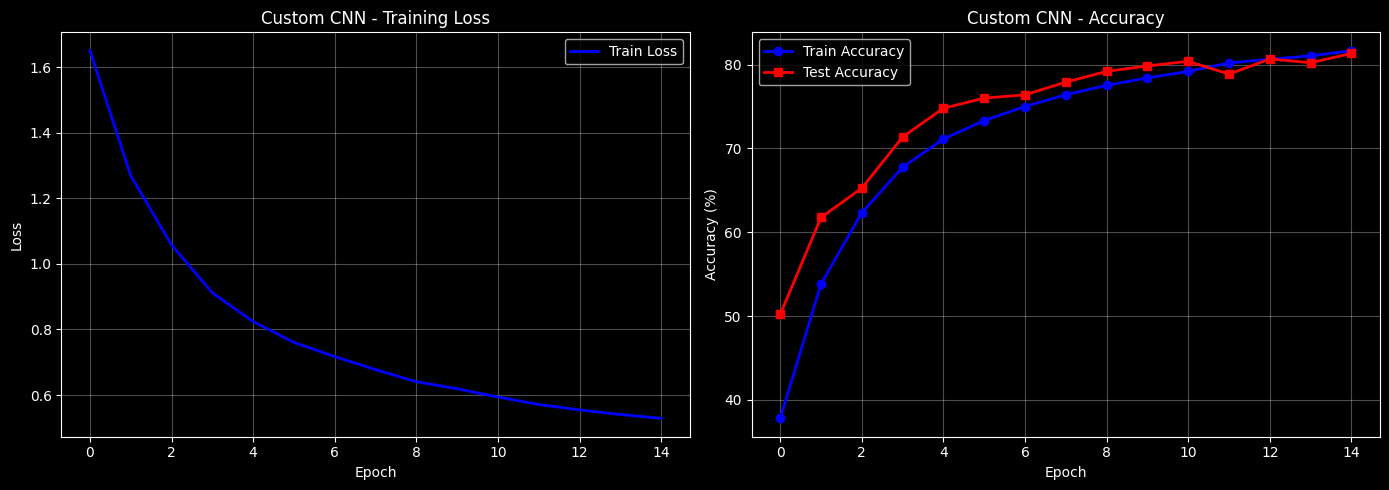

In [8]:
# plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, 'b-', linewidth=2, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Custom CNN - Training Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(train_accs, 'b-', linewidth=2, label='Train Accuracy', marker='o')
ax2.plot(test_accs, 'r-', linewidth=2, label='Test Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Custom CNN - Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Visualize Predictions

Let's see what our Custom CNN actually predicts on test images!

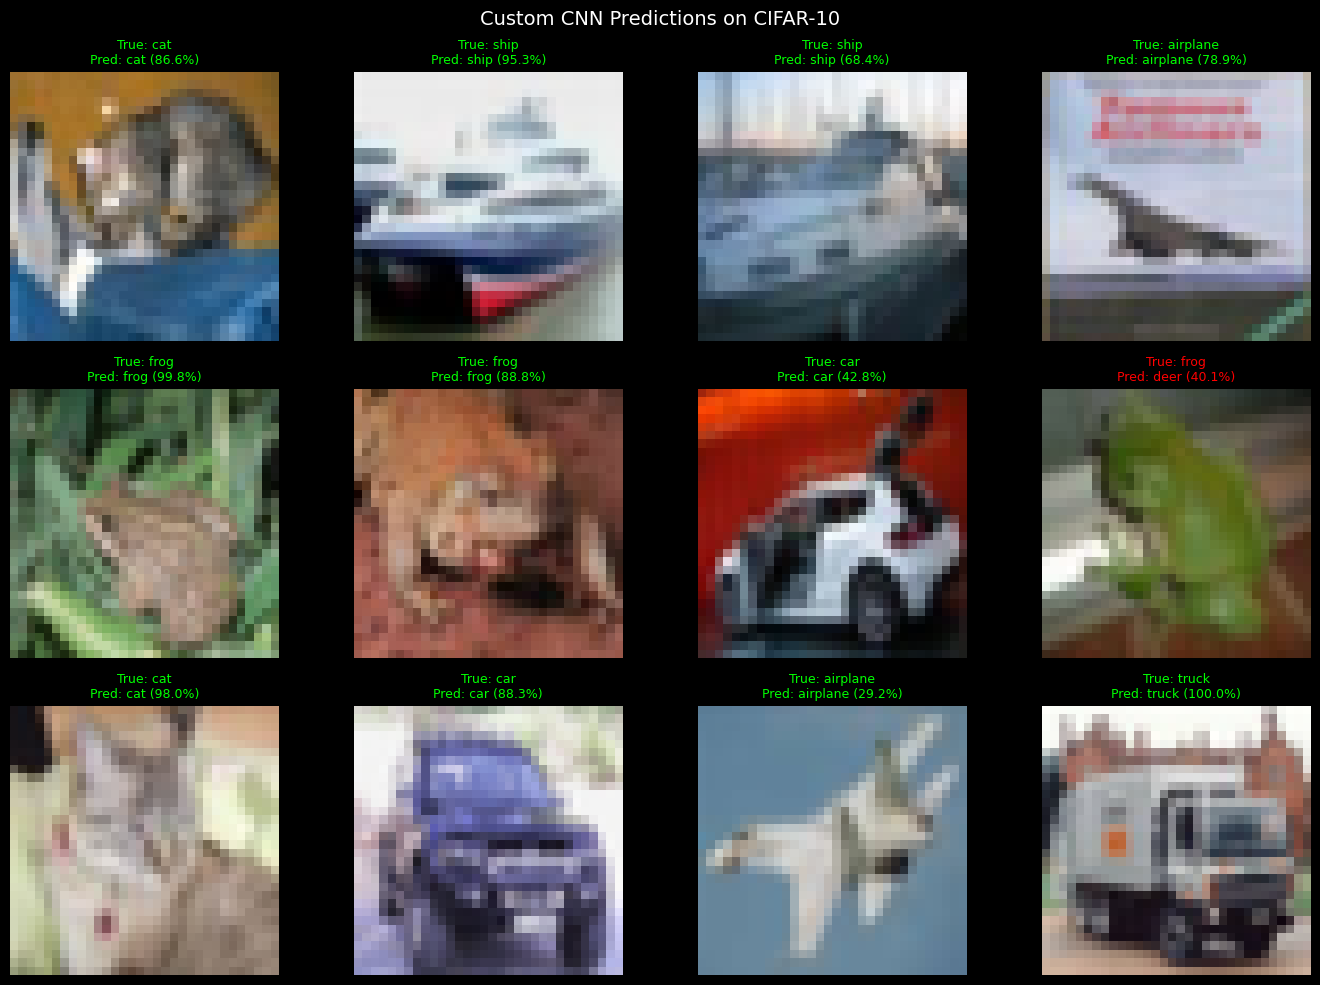


Batch Accuracy: 84.4%
Correct: 108/128


In [9]:
custom_cnn.eval()

dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = custom_cnn(images)
    _, predicted = outputs.max(1)
    probabilities = torch.softmax(outputs, dim=1)

# denormalize images for display
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1).to(device)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1).to(device)
images_denorm = images * std + mean

# plot predictions
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("Custom CNN Predictions on CIFAR-10", fontsize=14, y=0.98)

for idx, ax in enumerate(axes.flat):
    img = images_denorm[idx].cpu().permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    true_label = class_names[labels[idx]]
    pred_label = class_names[predicted[idx]]
    confidence = probabilities[idx][predicted[idx]].item() * 100

    ax.imshow(img)

    # color: green if correct, red if wrong
    color = 'lime' if predicted[idx] == labels[idx] else 'red'
    title = f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)"
    ax.set_title(title, fontsize=9, color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

# calculate accuracy on this batch
batch_acc = (predicted == labels).sum().item() / len(labels) * 100
print(f"\nBatch Accuracy: {batch_acc:.1f}%")
print(f"Correct: {(predicted == labels).sum().item()}/{len(labels)}")

---

<div dir="rtl" style="text-align: right; font-size: 22px; font-weight: bold; background-color: #1a1a2e; padding: 15px; border-radius: 10px;">

# part 2: Transfer Learning on Oxford Pets Dataset

</div>

**Now let's try a DIFFERENT task:** Classify cat and dog breeds using new custom data

**Oxford-IIIT Pet Dataset:**

- 37 pet breeds (25 dog breeds + 12 cat breeds)
- ~7,000 images
- Real-world varying sizes and backgrounds

**Transfer Learning with ResNet50:**

- Pre-trained on ImageNet (1.2M images, 1000 classes)
- We'll use it for pet breed classification (37 classes)

**Is that different from Part 1? ... ofcourse**

- Part 1: Built CNN from scratch on CIFAR-10
- Part 2: Use pre-trained ResNet50 on Oxford Pets
- Shows power of transfer learning on different dataset!


## Step 1: Load Oxford Pets Dataset

We'll use torchvision's built-in Oxford Pets dataset.

In [10]:
# Load Oxford-IIIT Pet Dataset from Google Drive
from torchvision.datasets import OxfordIIITPet
from torchvision.models import resnet50, ResNet50_Weights

# Define transforms for Oxford Pets (Data Augmentation)
transform_pets_train = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transform_pets_test = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

pets_train = OxfordIIITPet(root=DATA_PATH, split='trainval', download=False, transform=transform_pets_train)
pets_test = OxfordIIITPet(root=DATA_PATH, split='test', download=False, transform=transform_pets_test)

pets_train_loader = DataLoader(pets_train, batch_size=32, shuffle=True, num_workers=NUM_WORKERS)
pets_test_loader = DataLoader(pets_test, batch_size=32, shuffle=False, num_workers=NUM_WORKERS)

print(f"Oxford Pets Dataset loaded from Google Drive!")
print(f"Training samples: {len(pets_train)}")
print(f"Test samples: {len(pets_test)}")
print(f"Number of breeds: 37 (25 dogs + 12 cats)")
print(f"Image size: 224x224 (ResNet requirement)")

Oxford Pets Dataset loaded from Google Drive!
Training samples: 3680
Test samples: 3669
Number of breeds: 37 (25 dogs + 12 cats)
Image size: 224x224 (ResNet requirement)


## Step 2: Visualize Pet Breeds

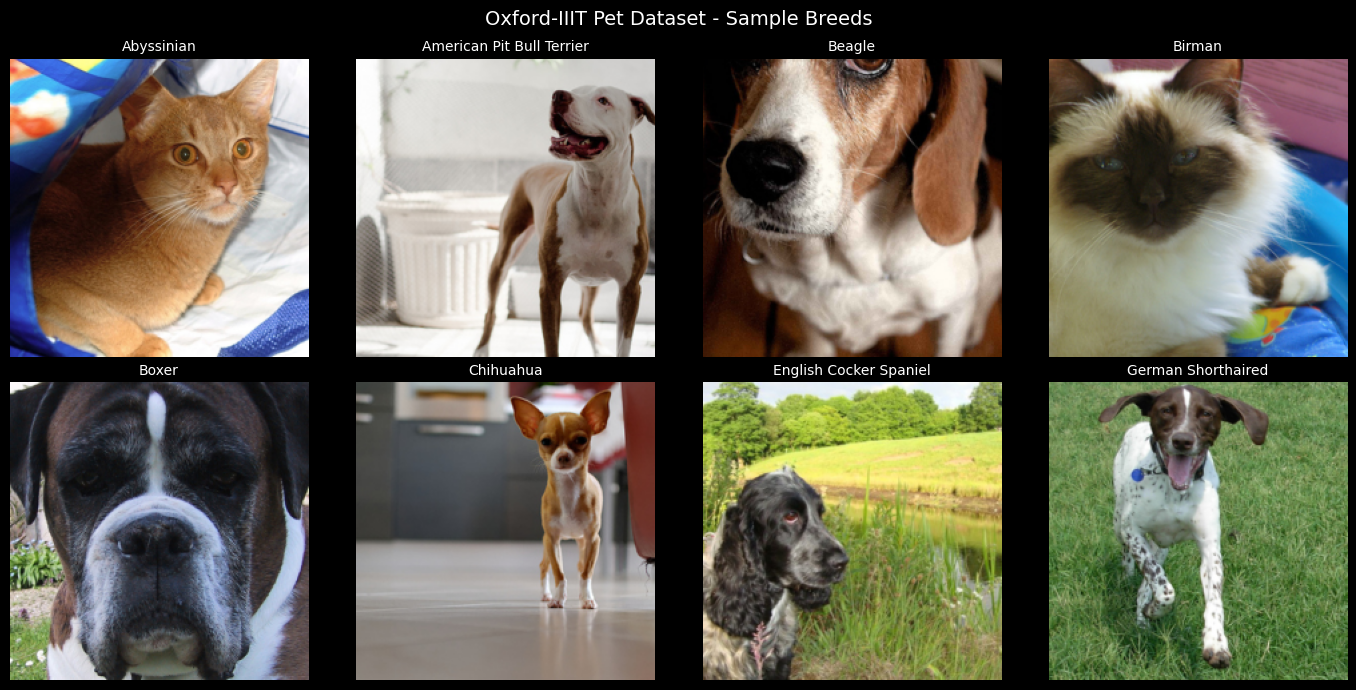

In [11]:
# Visualize some pet images
pets_display = OxfordIIITPet(root=DATA_PATH, split='trainval', download=False,
                             transform=transforms.Compose([
                                 transforms.Resize(256),
                                 transforms.CenterCrop(224),
                                 transforms.ToTensor()
                             ]))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle("Oxford-IIIT Pet Dataset - Sample Breeds", fontsize=14, y=0.98)

for i, ax in enumerate(axes.flat):
    img, label = pets_display[i * 100]
    ax.imshow(img.permute(1, 2, 0))
    breed_name = pets_display.classes[label].replace('_', ' ').title()
    ax.set_title(f"{breed_name}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()


## Step 3: Load Pre-trained ResNet50


**Transfer Learning Strategy:**

1. Load ResNet50 with ImageNet weights
2. Freeze ALL layers except final FC
3. Replace final FC for 37 pet breeds
4. Train only the final layer

In [12]:
# load pre-trained ResNet50
print("Loading pre-trained ResNet50...")
resnet_model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

print("\nResNet50 loaded!")
print(f"Pre-trained on: ImageNet (1.2M images, 1000 classes)")
print(f"Architecture: 50 layers with residual connections")

# freeze ALL layers
for param in resnet_model.parameters():
    param.requires_grad = False

print("\nFroze all layers")

# replace final FC layer
# ResNet50 has 2048 features before final FC
resnet_model.fc = nn.Linear(2048, 37)  # 37 pet breeds

resnet_model = resnet_model.to(device)

# count parameters
total_params = sum(p.numel() for p in resnet_model.parameters())
trainable_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)

print(f"\nResNet50 Transfer Learning:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,} (only final FC)")
print(f"Frozen parameters: {total_params - trainable_params:,}")
print(f"\nReady to train on Oxford Pets!")

Loading pre-trained ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 141MB/s]



ResNet50 loaded!
Pre-trained on: ImageNet (1.2M images, 1000 classes)
Architecture: 50 layers with residual connections

Froze all layers

ResNet50 Transfer Learning:
Total parameters: 23,583,845
Trainable parameters: 75,813 (only final FC)
Frozen parameters: 23,508,032

Ready to train on Oxford Pets!


## Step 4: Train ResNet50 on Pet Breeds

In [13]:
# train ResNet50 (only final layer)
print("Training ResNet50 Transfer Learning on Oxford Pets (20 epochs)...")
print("(Only training final FC layer - all other layers frozen)")

# use same train_model function from Part 1
resnet_train_losses, resnet_train_accs, resnet_test_accs = train_model(
    resnet_model, pets_train_loader, pets_test_loader, epochs=20, lr=0.001
)

print(f"\nTraining complete!")
print(f"Final Train Accuracy: {resnet_train_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {resnet_test_accs[-1]:.2f}%")
print(f"\nNote: Training only final layer is MUCH faster than training from scratch!")

Training ResNet50 Transfer Learning on Oxford Pets (20 epochs)...
(Only training final FC layer - all other layers frozen)
  Batch [50/115] Loss: 1.8053 Acc: 47.06%
  Batch [100/115] Loss: 1.3838 Acc: 64.22%

Epoch [1/20]
  Train: Loss=1.9366, Acc=66.60%
  Test: Acc=85.09%
------------------------------------------------------------
  Batch [50/115] Loss: 0.6025 Acc: 90.44%
  Batch [100/115] Loss: 0.5848 Acc: 89.81%

Epoch [2/20]
  Train: Loss=0.6691, Acc=89.76%
  Test: Acc=87.08%
------------------------------------------------------------
  Batch [50/115] Loss: 0.2917 Acc: 92.62%
  Batch [100/115] Loss: 0.4037 Acc: 92.41%

Epoch [3/20]
  Train: Loss=0.4262, Acc=92.42%
  Test: Acc=89.78%
------------------------------------------------------------
  Batch [50/115] Loss: 0.5574 Acc: 93.62%
  Batch [100/115] Loss: 0.3097 Acc: 94.06%

Epoch [4/20]
  Train: Loss=0.3208, Acc=94.10%
  Test: Acc=90.16%
------------------------------------------------------------
  Batch [50/115] Loss: 0.2177

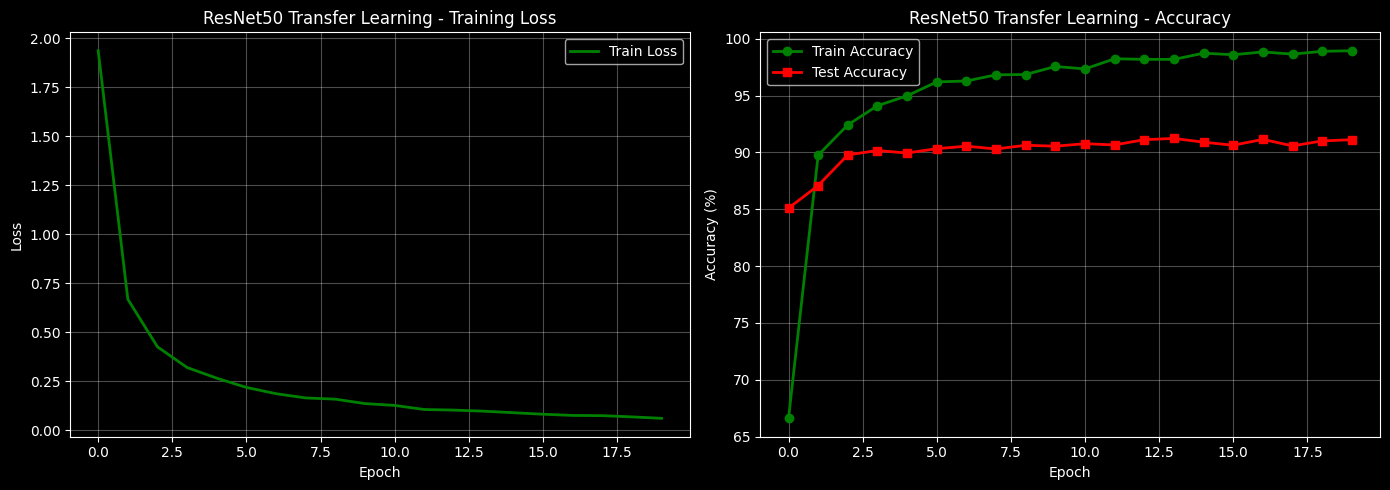

TRANSFER LEARNING RESULTS
ResNet50 (Transfer Learning): 91.11%

Task: Classify 37 pet breeds
Training time: ~5 minutes (20 epochs)
Parameters trained: 75,813 (only final layer)


In [14]:
# plot ResNet50 training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(resnet_train_losses, 'g-', linewidth=2, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('ResNet50 Transfer Learning - Training Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(resnet_train_accs, 'g-', linewidth=2, label='Train Accuracy', marker='o')
ax2.plot(resnet_test_accs, 'r-', linewidth=2, label='Test Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('ResNet50 Transfer Learning - Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("TRANSFER LEARNING RESULTS")
print(f"ResNet50 (Transfer Learning): {resnet_test_accs[-1]:.2f}%")
print(f"\nTask: Classify 37 pet breeds")
print(f"Training time: ~5 minutes (20 epochs)")
print(f"Parameters trained: {trainable_params:,} (only final layer)")

## Visualize ResNet Predictions

Let's see how ResNet50 classifies pet breeds!

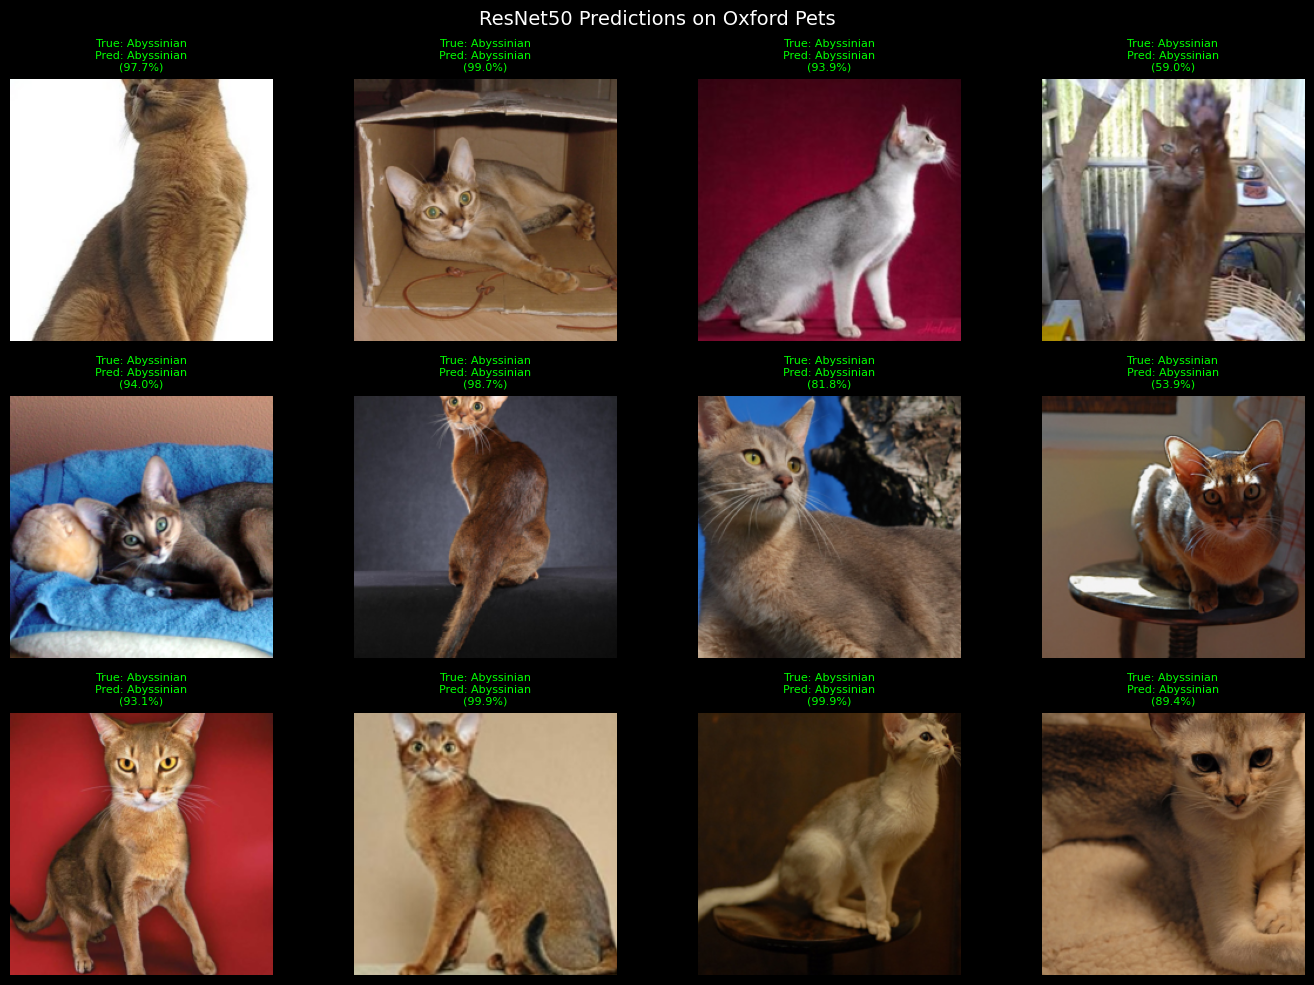


Batch Accuracy: 93.8%
Correct: 30/32

ResNet50 successfully classifies pet breeds!


In [15]:
# visualize ResNet50 predictions on pet breeds
resnet_model.eval()

# get a batch of test images
dataiter = iter(pets_test_loader)
next(dataiter)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = resnet_model(images)
    _, predicted = outputs.max(1)
    probabilities = torch.softmax(outputs, dim=1)

# denormalize images for display
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(device)
images_denorm = images * std + mean

# plot predictions
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("ResNet50 Predictions on Oxford Pets", fontsize=14, y=0.98)

for idx, ax in enumerate(axes.flat):
    img = images_denorm[idx].cpu().permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    true_label = pets_test.classes[labels[idx]].replace('_', ' ').title()
    pred_label = pets_test.classes[predicted[idx]].replace('_', ' ').title()
    confidence = probabilities[idx][predicted[idx]].item() * 100

    ax.imshow(img)

    # color: green if correct, red if wrong
    color = 'lime' if predicted[idx] == labels[idx] else 'red'
    title = f"True: {true_label}\nPred: {pred_label}\n({confidence:.1f}%)"
    ax.set_title(title, fontsize=8, color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

batch_acc = (predicted == labels).sum().item() / len(labels) * 100
print(f"\nBatch Accuracy: {batch_acc:.1f}%")
print(f"Correct: {(predicted == labels).sum().item()}/{len(labels)}")
print(f"\nResNet50 successfully classifies pet breeds!")

---

<div dir="rtl" style="text-align: right; font-size: 22px; font-weight: bold; background-color: #1a1a2e; padding: 15px; border-radius: 10px;">

# part 2.5: YOLO Object Detection

</div>

**YOLO (You Only Look Once)**

**Differences from Classification:**

- **Classification:** "What is this image?" → Single label
- **Object Detection:** "What objects are where?" → Multiple bounding boxes + labels

**YOLO Advantages:**

- Real-time speed
- Detects multiple objects per image
- Provides bounding boxes + confidence scores
- Used in self-driving cars, surveillance, robotics and many more custom applications as discussed in the lecture

**In this section:**

1. Run YOLO inference on sample images
2. Fine-tune YOLO on new problem: pothole detection dataset



## Step 1: Install Ultralytics YOLO

We'll use YOLOv8 from Ultralytics.

In [16]:
from ultralytics import YOLO
import cv2
import glob
import os
from pathlib import Path
import shutil


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Step 2: YOLO Inference on Pre-trained Model

We'll load YOLOv8n (nano version - fastest) pre-trained on COCO dataset (80 classes).

In [17]:
# Check for pothole dataset
import glob

if not os.path.exists(POTHOLE_PATH):
    print(f"ERROR: Pothole Dataset not found at: {POTHOLE_PATH}")
    print("\nMake sure the folder structure is correct in Google Drive:")
    print("  My Drive/week11_data/Pothole Dataset/")
    pothole_images = []
    valid_pairs = []
else:
    print(f"Found pothole dataset at: {POTHOLE_PATH}")

    # Get all pothole images
    pothole_images = sorted(glob.glob(os.path.join(POTHOLE_PATH, "*.jpg")))
    pothole_images = [img for img in pothole_images if "README" not in img.lower()]

    print(f"Found {len(pothole_images)} images")

    # Check for corresponding labels
    pothole_labels = [img.replace('.jpg', '.txt') for img in pothole_images]
    valid_pairs = [(img, lbl) for img, lbl in zip(pothole_images, pothole_labels) if os.path.exists(lbl)]

    print(f"Found {len(valid_pairs)} image-label pairs")

    if len(pothole_images) > 0:
        print(f"\nSample images:")
        for i in range(min(3, len(pothole_images))):
            print(f"  {os.path.basename(pothole_images[i])}")

Found pothole dataset at: /content/week11_data/Pothole Dataset
Found 1243 images
Found 1243 image-label pairs

Sample images:
  img-1.jpg
  img-10.jpg
  img-100.jpg


In [18]:
# Load pre-trained YOLOv8n (trained on COCO dataset)
print("Loading YOLOv8n (pre-trained on COCO)...")

yolo_model = YOLO('yolov8n.pt')

print("YOLOv8n loaded!")
print(f"\nModel info:")
print(f"  Pre-trained on: COCO dataset (80 classes)")
print(f"  Classes include: person, car, bicycle, dog, cat, etc.")
print(f"  Does NOT include: pothole (yet!)")

Loading YOLOv8n (pre-trained on COCO)...
YOLOv8n loaded!

Model info:
  Pre-trained on: COCO dataset (80 classes)
  Classes include: person, car, bicycle, dog, cat, etc.
  Does NOT include: pothole (yet!)


Running YOLO inference on 6 pothole images...
Note: Pre-trained model doesn't know 'pothole' class, so may detect other objects



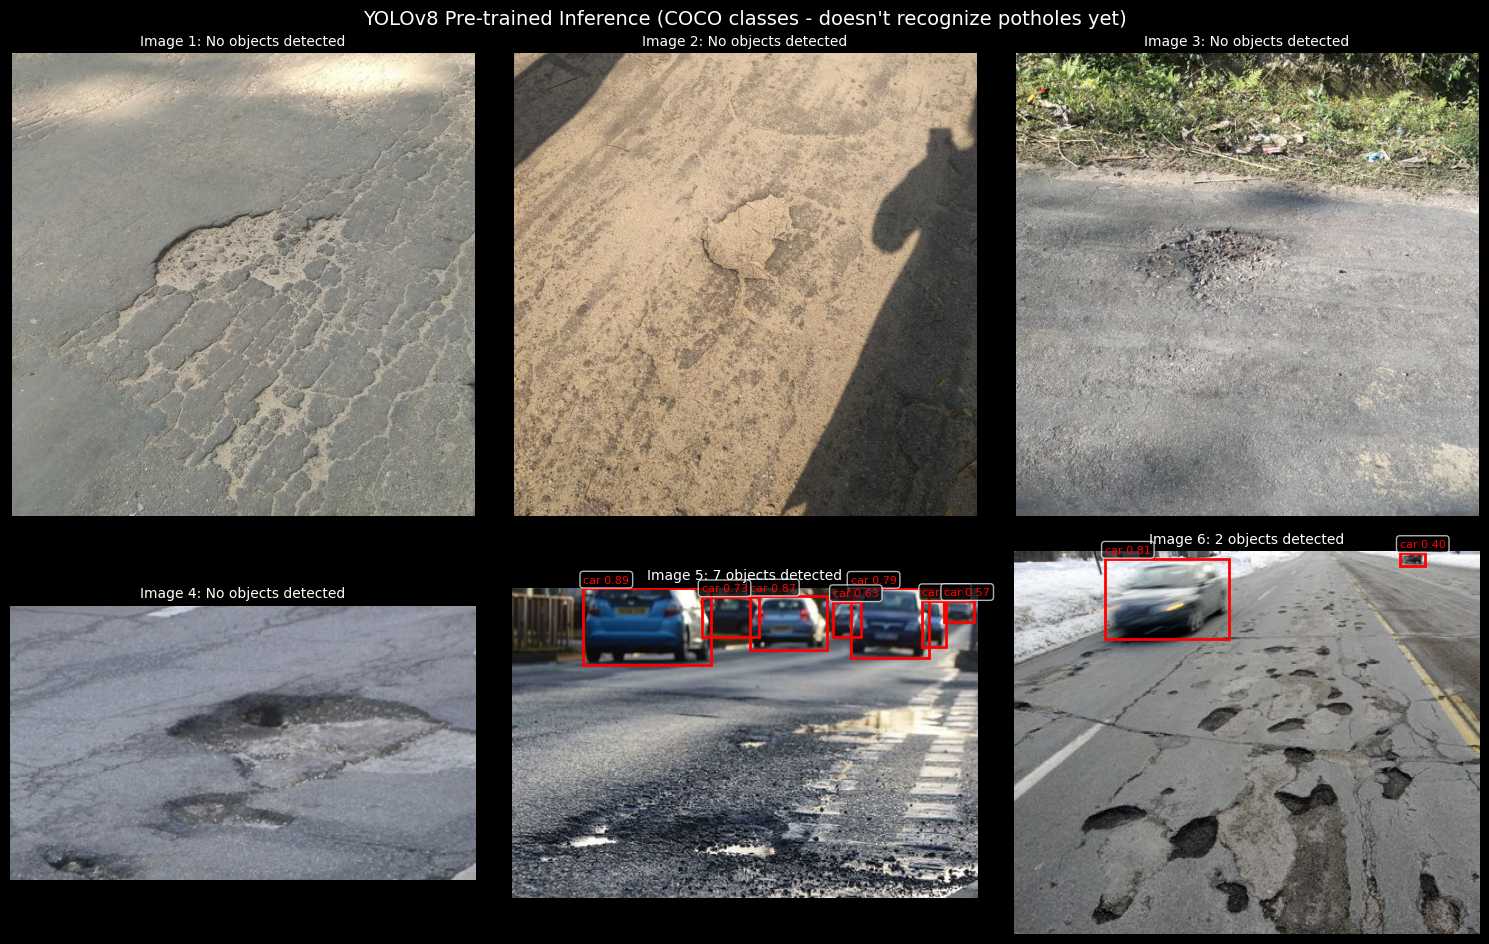

In [19]:
# Run YOLO inference on pothole images (using pre-trained COCO model)
if len(pothole_images) == 0:
    print("ERROR: No pothole images found!")
    print("Please run the 'check for pothole dataset' cell and ensure the dataset exists on Google Drive.")
else:
    print(f"Running YOLO inference on {min(6, len(pothole_images))} pothole images...")
    print("Note: Pre-trained model doesn't know 'pothole' class, so may detect other objects\n")

    sample_images = pothole_images[:6]
    results = yolo_model.predict(sample_images, conf=0.25, verbose=False)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle("YOLOv8 Pre-trained Inference (COCO classes - doesn't recognize potholes yet)",
                 fontsize=14, y=0.98)

    for idx, (ax, result) in enumerate(zip(axes.flat, results)):
        img = result.orig_img
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img_rgb)

        if len(result.boxes) > 0:
            for box in result.boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                conf = box.conf[0].cpu().numpy()
                cls = int(box.cls[0].cpu().numpy())
                label = f"{result.names[cls]} {conf:.2f}"

                rect = plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                      fill=False, edgecolor='red', linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1-5, label, color='red', fontsize=8,
                        bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))

            ax.set_title(f"Image {idx+1}: {len(result.boxes)} objects detected", fontsize=10)
        else:
            ax.set_title(f"Image {idx+1}: No objects detected", fontsize=10)

        ax.axis('off')

    plt.tight_layout()
    plt.show()

## Step 3: Fine-tune YOLO on Pothole Dataset

**Fine-tuning Strategy:**

1. Prepare dataset in YOLO format (images + labels)
2. Split into train/val sets
3. Create data.yaml config file (Note how we configure this differently for YOLO and the model reads the configuration from .yaml file)
4. Fine-tune YOLOv8n on pothole data
5. Evaluate and visualize results


In [20]:
import shutil
import random

if len(pothole_images) == 0:
    print("ERROR: No pothole images found! Run the dataset check cell first.")
else:
    YOLO_DATASET_PATH = "/content/yolo_pothole_dataset"

    os.makedirs(f"{YOLO_DATASET_PATH}/train/images", exist_ok=True)
    os.makedirs(f"{YOLO_DATASET_PATH}/train/labels", exist_ok=True)
    os.makedirs(f"{YOLO_DATASET_PATH}/val/images", exist_ok=True)
    os.makedirs(f"{YOLO_DATASET_PATH}/val/labels", exist_ok=True)

    all_images = pothole_images
    all_labels = [img.replace('.jpg', '.txt') for img in all_images]
    valid_pairs = [(img, lbl) for img, lbl in zip(all_images, all_labels) if os.path.exists(lbl)]

    print(f"Total valid image-label pairs: {len(valid_pairs)}")

    random.seed(42)
    if len(valid_pairs) > 500:
        valid_pairs = random.sample(valid_pairs, 500)
        print(f"Using small subset: {len(valid_pairs)} images (for fast demo)")

    # Split 80/20
    num_train = int(0.8 * len(valid_pairs))
    indices = list(range(len(valid_pairs)))
    random.shuffle(indices)

    train_indices = indices[:num_train]
    val_indices = indices[num_train:]

    print(f"\nDataset split:")
    print(f"  Train samples: {len(train_indices)}")
    print(f"  Val samples: {len(val_indices)}")

    print("\nCopying files to YOLO structure...")
    for idx in train_indices:
        img_src, lbl_src = valid_pairs[idx]
        img_name = os.path.basename(img_src)
        lbl_name = os.path.basename(lbl_src)

        shutil.copy(img_src, f"{YOLO_DATASET_PATH}/train/images/{img_name}")
        shutil.copy(lbl_src, f"{YOLO_DATASET_PATH}/train/labels/{lbl_name}")

    for idx in val_indices:
        img_src, lbl_src = valid_pairs[idx]
        img_name = os.path.basename(img_src)
        lbl_name = os.path.basename(lbl_src)

        shutil.copy(img_src, f"{YOLO_DATASET_PATH}/val/images/{img_name}")
        shutil.copy(lbl_src, f"{YOLO_DATASET_PATH}/val/labels/{lbl_name}")

    # Create data.yaml config file
    yaml_content = f"""
    path: {YOLO_DATASET_PATH}
    train: {YOLO_DATASET_PATH}/train/images
    val: {YOLO_DATASET_PATH}/val/images

    nc: 1
    names: ['pothole']
    """

    with open(f"{YOLO_DATASET_PATH}/data.yaml", 'w') as f:
      f.write(yaml_content)

    print(f"Dataset prepared!")
    print(f"Config: {YOLO_DATASET_PATH}/data.yaml")
    print(f"\nNote: Using local Colab storage for faster training")

Total valid image-label pairs: 1243
Using small subset: 500 images (for fast demo)

Dataset split:
  Train samples: 400
  Val samples: 100

Copying files to YOLO structure...
Dataset prepared!
Config: /content/yolo_pothole_dataset/data.yaml

Note: Using local Colab storage for faster training


In [21]:
print("Fine-tuning YOLOv8n on pothole dataset...")
print("Settings for quick demonstration:")
print("  - Epochs: 3")
print("  - Image size: 320 (small resolution)")
print("  - Batch size: 32")
print("  - Dataset: 100 images")
print("\nExpected time: ~2-3 minutes on Colab GPU")

yolo_finetune = YOLO('yolov8n.pt')

results_train = yolo_finetune.train(
    data=f"{YOLO_DATASET_PATH}/data.yaml",
    epochs=20,
    imgsz=640,       # standard YOLO size for good detail detection, we could make that smaller for faster execution
    batch=16,
    name='pothole_yolo',
    patience=5,
    save=True,
    plots=True,      # turn on plots to see the results.png in the runs folder
    verbose=True,
    device=0 if torch.cuda.is_available() else 'cpu'
)

weights_path = str(yolo_finetune.trainer.best)

print("\nFine-tuning complete!")
print(f"Model saved to: {weights_path}")

globals()['YOLO_MODEL_PATH'] = weights_path

if os.path.exists(weights_path):
    print(f"Model file verified: {os.path.getsize(weights_path) / (1024*1024):.1f} MB")

Fine-tuning YOLOv8n on pothole dataset...
Settings for quick demonstration:
  - Epochs: 3
  - Image size: 320 (small resolution)
  - Batch size: 32
  - Dataset: 100 images

Expected time: ~2-3 minutes on Colab GPU
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None,

## Step 4: Evaluate Fine-tuned YOLO

Now let's test the fine-tuned model and compare with pre-trained!

Loading fine-tuned YOLO model...
path is: /content/runs/detect/pothole_yolo/weights/best.pt

Evaluating on validation set...
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3206.6±2035.0 MB/s, size: 489.7 KB)
val: Scanning /content/yolo_pothole_dataset/val/labels.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 41.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.6it/s 2.0s
                   all        100        349      0.714      0.464       0.55      0.266
Speed: 1.8ms preprocess, 4.8ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/detect/val

FINE-TUNED YOLO METRICS ON POTHOLE DETECTION
mAP50: 0.5497
mAP50-95: 0.2655
Precision: 0.7142
Recall: 0.4642

Testing on 6 images...


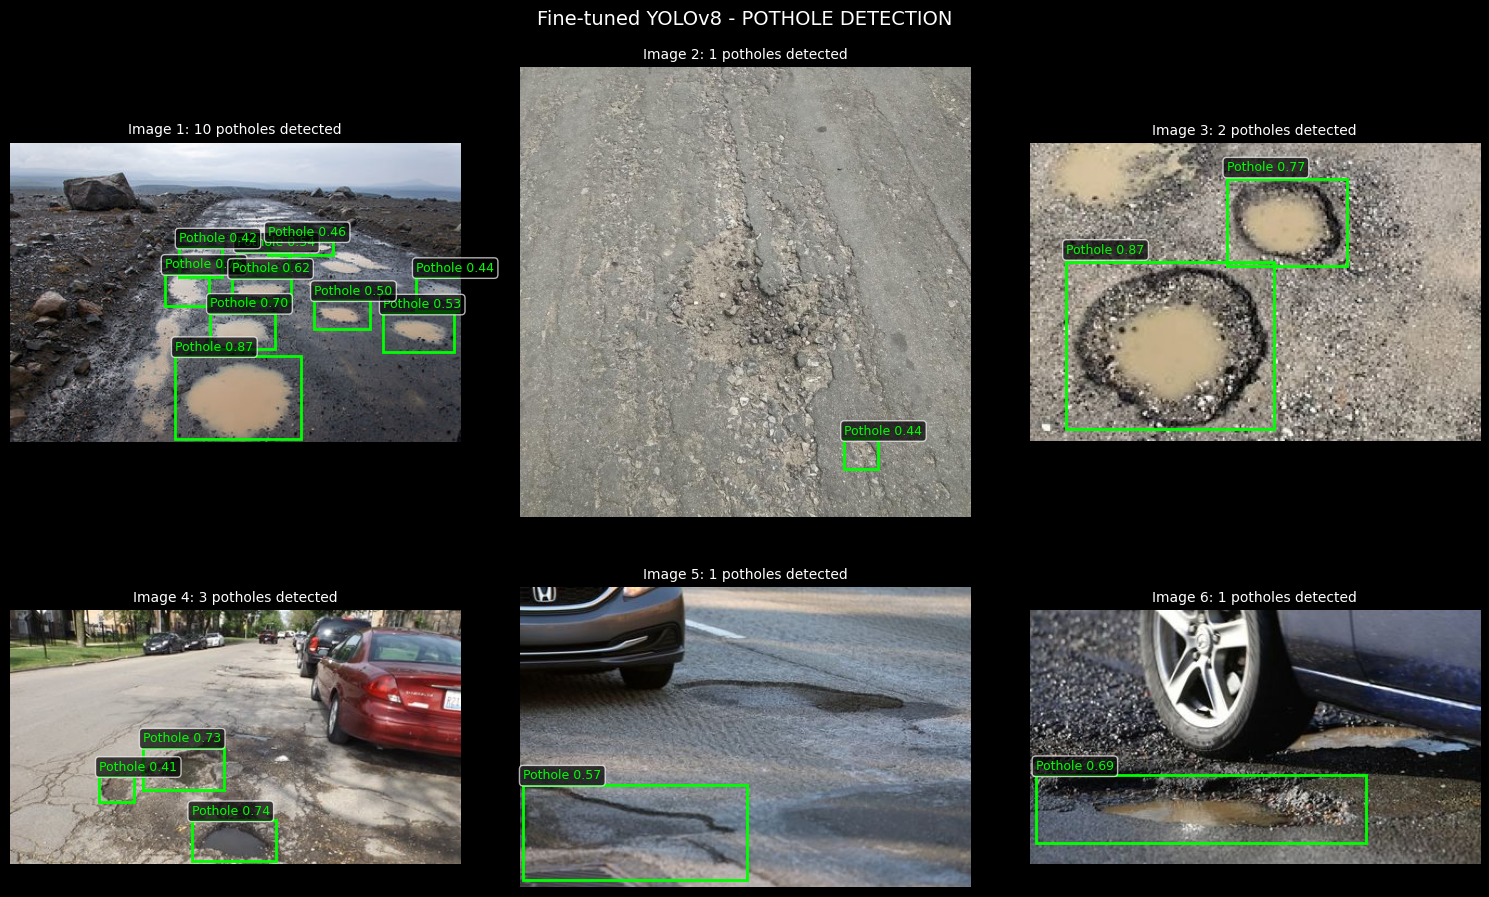


SUCCESS! Fine-tuned YOLO detects potholes!

Comparison:
  Pre-trained YOLO: Detects common objects (person, car, etc.)
  Fine-tuned YOLO: Detects POTHOLES specifically!


In [22]:
import glob

YOLO_MODEL_PATH = globals().get('YOLO_MODEL_PATH', None)

if YOLO_MODEL_PATH is None or not os.path.exists(YOLO_MODEL_PATH):
    possible_paths = glob.glob('/content/runs/detect/pothole_yolo/weights/best.pt')
    if possible_paths:
        YOLO_MODEL_PATH = sorted(possible_paths)[-1]  # Get the latest
        print(f"Found model at: {YOLO_MODEL_PATH}")
    else:
        print("ERROR: Fine-tuned model not found!")
        print("Please run the training cell first.")
        YOLO_MODEL_PATH = None

if YOLO_MODEL_PATH and os.path.exists(YOLO_MODEL_PATH):
    print("Loading fine-tuned YOLO model...")
    yolo_finetuned = YOLO(YOLO_MODEL_PATH)

    print("path is: "+ YOLO_MODEL_PATH)
    print("\nEvaluating on validation set...")
    metrics = yolo_finetuned.val(data=f"{YOLO_DATASET_PATH}/data.yaml", verbose=False)

    print("\nFINE-TUNED YOLO METRICS ON POTHOLE DETECTION")
    print(f"mAP50: {metrics.box.map50:.4f}")
    print(f"mAP50-95: {metrics.box.map:.4f}")
    print(f"Precision: {metrics.box.mp:.4f}")
    print(f"Recall: {metrics.box.mr:.4f}")

    val_images_list = sorted(glob.glob(f"{YOLO_DATASET_PATH}/val/images/*.jpg"))[:6]

    if len(val_images_list) == 0:
        val_images_list = pothole_images[:6]

    print(f"\nTesting on {len(val_images_list)} images...")
    results_finetuned = yolo_finetuned.predict(val_images_list, conf=0.40, verbose=False)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle("Fine-tuned YOLOv8 - POTHOLE DETECTION", fontsize=14, y=0.98)

    for idx, (ax, result) in enumerate(zip(axes.flat, results_finetuned)):
        img = result.orig_img
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img_rgb)

        if len(result.boxes) > 0:
            for box in result.boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                conf = box.conf[0].cpu().numpy()
                label = f"Pothole {conf:.2f}"

                rect = plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                      fill=False, edgecolor='lime', linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1-5, label, color='lime', fontsize=9,
                        bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))

            ax.set_title(f"Image {idx+1}: {len(result.boxes)} potholes detected", fontsize=10)
        else:
            ax.set_title(f"Image {idx+1}: No potholes detected", fontsize=10)

        ax.axis('off')

    plt.tight_layout()
    plt.show()

    print("\nSUCCESS! Fine-tuned YOLO detects potholes!")
    print("\nComparison:")
    print("  Pre-trained YOLO: Detects common objects (person, car, etc.)")
    print("  Fine-tuned YOLO: Detects POTHOLES specifically!")

---

<div dir="rtl" style="text-align: right; font-size: 22px; font-weight: bold; background-color: #1a1a2e; padding: 15px; border-radius: 10px;">

# part 3: Practice Exercises

</div>

Now it's your turn! Complete the following exercises to solidify your understanding.


## Exercise 1: Build a Deeper CNN (5 points)

**Task:** Create a CNN with **4 convolutional blocks** instead of 3.

**Architecture to implement:**
```
Conv Block 1: Conv2d(3→32) → ReLU → MaxPool2d → Dropout(0.2)
Conv Block 2: Conv2d(32→64) → ReLU → MaxPool2d → Dropout(0.3)
Conv Block 3: Conv2d(64→128) → ReLU → MaxPool2d → Dropout(0.4)
Conv Block 4: Conv2d(128→256) → ReLU → MaxPool2d → Dropout(0.4)  # NEW!
FC Block: Flatten → Linear(1024→512) → ReLU → Dropout(0.5) → Linear(512→num_classes)
```

**Hints:**
- After 4 MaxPool2d layers (each 2x2), a 32x32 image becomes 2x2
- FC input size = 256 * 2 * 2 = 1024
- Use `kernel_size=3, padding=1` for Conv2d layers


In [23]:
# Exercise 1: Build Deeper CNN
class DeeperCNN(nn.Module):
    """Deeper CNN with 4 convolutional blocks"""

    def __init__(self, num_classes=10):
        super(DeeperCNN, self).__init__()

        ### BEGIN SOLUTION
        # YOUR CODE HERE
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32,32,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2 , stride=2),
            nn.Dropout(.2)
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64,64,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2 , stride=2),
            nn.Dropout(.3)
        )
        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128,128,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2 , stride=2),
            nn.Dropout(.4)
        )
        self.conv_block4 = nn.Sequential(
            nn.Conv2d(128,256,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256,256,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2 , stride=2),
            nn.Dropout(.4)
        )
        self.fc_block = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024,512),
            nn.ReLU(inplace=True),
            nn.Dropout(.5),
            nn.Linear(512,num_classes)
        )

        ### END SOLUTION

    def forward(self, x):
        ### BEGIN SOLUTION
        # YOUR CODE HERE
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.fc_block(x)
        return x

        ### END SOLUTION

# test your model
deeper_cnn = DeeperCNN(num_classes=10).to(device)
test_input = torch.randn(1, 3, 32, 32).to(device)
test_output = deeper_cnn(test_input)

print(f"Model created successfully!")
print(f"Input shape: {test_input.shape}")
print(f"Output shape: {test_output.shape}")
print(f"Parameters: {sum(p.numel() for p in deeper_cnn.parameters()):,}")

Model created successfully!
Input shape: torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
Parameters: 1,702,186


In [24]:
# tests for Exercise 1
# Your DeeperCNN model will be tested for:
# - Being a valid nn.Module
# - Correct output shape [batch_size, 10]
# - Having more than 500K parameters (4 conv blocks)

# Visible test: check model exists
assert 'deeper_cnn' in dir(), "deeper_cnn model should be defined"
print("Visible test passed! Hidden tests will run during grading.")


Visible test passed! Hidden tests will run during grading.


## Exercise 2: Transfer Learning with ResNet18 (5 points)

**Task:** Use ResNet18 for transfer learning on CIFAR-10.

**Steps to implement:**
1. Load pre-trained ResNet18 using `resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)`
2. Freeze all layers: `for param in resnet.parameters(): param.requires_grad = False`
3. Replace final FC layer: `resnet.fc = nn.Linear(512, 10)` (ResNet18 has 512 features)
4. Move to device and train for 3 epochs

**Hints:**
- The variable must be named `resnet`
- Use the provided `train_model()` function
- Store results in `resnet_losses`, `resnet_train_accs`, `resnet_test_accs`


In [26]:
# Exercise 2: Transfer Learning with ResNet18
from torchvision.models import resnet18, ResNet18_Weights

### BEGIN SOLUTION
# YOUR CODE HERE
resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

for param in resnet.parameters():
    param.requires_grad = False

resnet.fc = nn.Linear(512,10)  # 37 pet breeds

resnet_model = resnet.to(device)
### END SOLUTION

print("ResNet18 loaded and adapted for CIFAR-10!")

ResNet18 loaded and adapted for CIFAR-10!


In [27]:
# train ResNet18 for 3 epochs
### BEGIN SOLUTION
# YOUR CODE HERE
resnet_losses, resnet_train_accs, resnet_test_accs = train_model(
    resnet_model, train_loader, test_loader, epochs=3, lr=0.001
)### END SOLUTION

  Batch [50/391] Loss: 1.9297 Acc: 23.61%
  Batch [100/391] Loss: 1.8211 Acc: 29.51%
  Batch [150/391] Loss: 1.6440 Acc: 32.77%
  Batch [200/391] Loss: 1.7904 Acc: 34.62%
  Batch [250/391] Loss: 1.8009 Acc: 35.97%
  Batch [300/391] Loss: 1.6562 Acc: 37.29%
  Batch [350/391] Loss: 1.7056 Acc: 38.18%

Epoch [1/3]
  Train: Loss=1.7598, Acc=38.64%
  Test: Acc=44.27%
------------------------------------------------------------
  Batch [50/391] Loss: 1.6897 Acc: 43.70%
  Batch [100/391] Loss: 1.6742 Acc: 44.28%
  Batch [150/391] Loss: 1.5813 Acc: 44.56%
  Batch [200/391] Loss: 1.5123 Acc: 44.43%
  Batch [250/391] Loss: 1.4938 Acc: 44.35%
  Batch [300/391] Loss: 1.6367 Acc: 44.24%
  Batch [350/391] Loss: 1.5423 Acc: 44.45%

Epoch [2/3]
  Train: Loss=1.5884, Acc=44.66%
  Test: Acc=45.08%
------------------------------------------------------------
  Batch [50/391] Loss: 1.4070 Acc: 46.72%
  Batch [100/391] Loss: 1.5254 Acc: 46.09%
  Batch [150/391] Loss: 1.4442 Acc: 45.84%
  Batch [200/391] Lo

In [28]:
# tests for Exercise 2
# Your ResNet18 transfer learning will be tested for:
# - Being a valid nn.Module
# - Having 'fc' attribute (final layer)
# - Final layer outputting 10 classes
# - Training for exactly 3 epochs

# Visible test: check resnet exists
assert 'resnet' in dir(), "resnet model should be defined"
print("Visible test passed! Hidden tests will run during grading.")


Visible test passed! Hidden tests will run during grading.


## Exercise 3: Experiment with Data Augmentation (5 points)

**Task:** Train your DeeperCNN with **stronger data augmentation**.

**Augmentations to use:**
```python
transforms.RandomHorizontalFlip(p=0.5)
transforms.RandomCrop(32, padding=4)
transforms.ColorJitter(brightness=0.2, contrast=0.2)
transforms.RandomRotation(degrees=15)
transforms.ToTensor()
transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2470, 0.2435, 0.2616])
```

**Steps:**
1. Create `transform_augmented` with the above transforms
2. Create new dataset and dataloader with augmentation
3. Create a new `DeeperCNN` model named `deeper_cnn_aug`
4. Train for 3 epochs, storing results in `aug_losses`, `aug_train_accs`, `aug_test_accs`


In [29]:
# Exercise 3: Stronger Data Augmentation
### BEGIN SOLUTION
# YOUR CODE HERE

transform_augmented = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2470, 0.2435, 0.2616]),
])

aug_dataset = torchvision.datasets.CIFAR10(root=DATA_PATH , train=True, download=True, transform=transform_augmented)
aug_loader = torch.utils.data.DataLoader(aug_dataset, batch_size=128, shuffle=True)

deeper_cnn_aug = DeeperCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(deeper_cnn_aug.parameters(), lr=0.001)

aug_losses, aug_train_accs, aug_test_accs = [], [], []

for epoch in range(3):
    deeper_cnn_aug.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in aug_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = deeper_cnn_aug(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    aug_losses.append(running_loss / len(aug_loader))
    aug_train_accs.append(100 * correct / total)

    deeper_cnn_aug.eval()
    t_correct, t_total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            t_correct += (deeper_cnn_aug(images).argmax(1) == labels).sum().item()
            t_total += labels.size(0)
    aug_test_accs.append(100 * t_correct / t_total)
    print(f"Epoch {epoch+1}: loss={aug_losses[-1]:.4f}, train={aug_train_accs[-1]:.2f}%, test={aug_test_accs[-1]:.2f}%")

### END SOLUTION

Epoch 1: loss=1.9784, train=24.51%, test=39.28%
Epoch 2: loss=1.6024, train=39.57%, test=49.09%
Epoch 3: loss=1.4156, train=48.09%, test=54.45%


In [30]:
# tests for Exercise 3
# Your data augmentation experiment will be tested for:
# - Training for exactly 3 epochs
# - Achieving test accuracy > 50%

# Visible test: check training results exist
assert 'aug_test_accs' in dir(), "aug_test_accs should be defined after training"
print("Visible test passed! Hidden tests will run during grading.")


Visible test passed! Hidden tests will run during grading.


---

<div dir="rtl" style="text-align: right; font-size: 24px; font-weight: bold; background: linear-gradient(135deg, #1a1a2e 0%, #16213e 100%); padding: 20px; border-radius: 10px;">

مبروك! خلصت Week 11 بنجاح والحمد لله

</div>
